# Lab 2.2: A Language Model Without Attention — char-level RNN, backprop through time, and the measured death of gradient signal

**Language-model internals series.** [Lab 2.1](/posts/ml/labs/2026-10-27-lab-2-1-how-word-vectors-learn-to-mean/) gave words geometry without any sequence at all — windows don't know order. This lab puts order back, the pre-2017 way: a recurrent network that reads one character at a time and carries everything it remembers in one vector.

The organizing question of this series, sharpened:

> Instead of predicting from a window, a recurrent network passes information forward through a *state*: $h_t = f(x_t, h_{t-1})$. The same weights process every time step. What does that actually buy — and what does the state charge for it?

Plan:

1. Implement a vanilla char-RNN in NumPy — forward unrolled, **backprop through time deriving every gradient by hand**, finite-difference ritual as always.
2. Train it on the first 200k characters of tiny-Shakespeare (Karpathy's corpus) until it babbles passable fake-English, watching the loss fall and sampling text.
3. Open the state itself: hidden-activation heatmaps over a prompt, predictions evolving as characters arrive.
4. Then the measurement this series exists for: **how does information die as it travels through time?** Two curves — the *forward* decay of an input perturbation's echo through $h$, and the *backward* decay of the BPTT gradient arriving from a distant loss — plus the single number that theory says controls both: $\sigma_{\max}(W_{hh})$.

Prereqs: your [backprop notes](/posts/ml/2026-09-12-3-backpropagation-in-a-fully-connected-network) transfer 1:1 — an unrolled RNN *is* a deep feed-forward net with shared weights, and that observation will do real work below.

## 0. Setup

First 200k characters of tiny-Shakespeare (~90% of which is real training signal for a tiny model); character vocab (~65 symbols), so the "tokenizer" is a dict. One honest warning before we start: training an RNN in NumPy means Python loops through time — everything below is deliberately small (hidden 128, seq 50) so the lab runs in about a minute. (Lab 2.5 will move to PyTorch on the M3's GPU; scaling is a different lesson from understanding.)

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from lm_lab import save_ckpt, load_ckpt, manifest

text = Path("data/tiny-shakespeare.txt").read_text()
text = text[:200_000]
chars = sorted(set(text))
c2i = {c: i for i, c in enumerate(chars)}
i2c = {i: c for c, i in c2i.items()}
V = len(chars)
data = np.array([c2i[c] for c in text], dtype=np.int32)

CKPT = Path("checkpoints/lab22"); FIGS = Path("figures/lab22"); FIGS.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(11)
print(f"corpus: {len(data):,} chars | vocab: {V} | head: {''.join(i2c[i] for i in data[:50])!r}")

corpus: 200,000 chars | vocab: 62 | head: 'First Citizen:\nBefore we proceed any further, hear'


## 1. The model and the gradients, on paper first

**Forward**, per time step $t$ (batch implied):
$$x_t = E[\text{id}_t], \qquad h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h), \qquad z_t = W_{hy}\,h_t + b_y, \qquad \hat p_t = \mathrm{softmax}(z_t)$$

Loss: mean cross-entropy of predicting character $t{+}1$ at every position $t$.

**Backward.** Unroll the net over $T$ steps — it is a fully-connected net of depth $T$ **with shared weights**, so each parameter's gradient is the *sum* of its per-step contributions ("gradients add at branch points" — your notes). Let $g_t = \partial L / \partial z_t = \frac1{BT}(\hat p_t - y_t)$. Define the two gradient carriers through time:

$$\delta_t \equiv \frac{\partial L}{\partial a_t} = \bigl(W_{hy}^{\top} g_t + W_{hh}^{\top}\delta_{t+1} \odot (1-\tanh^2(a_{t+1}))\bigr) \odot (1 - \tanh^2(a_t))$$

(compare with the dense derivation you know: same rule, with the transported term arriving from the *future* through $W_{hh}$ inside its own tanh gate). Then:

$$\frac{\partial L}{\partial W_{hh}} = \sum_t \delta_t \odot (1-\tanh^2(a_t))\; h_{t-1}^{\top}, \qquad \frac{\partial L}{\partial W_{xh}} = \sum_t (\cdot)\; x_t^{\top}, \qquad \frac{\partial L}{\partial W_{hy}} = \sum_t g_t\, h_t^{\top}$$

The transported term is the whole story of §5: each step back multiplies by (roughly) $W_{hh}^{\top}\mathrm{diag}(1-h^2)$, a Jacobian product across time. We'll implement this, verify it entry-by-entry with finite differences, and then *measure its norm*.

In [2]:
class CharRNN:
    """h_t = tanh(Wx x_t + Wh h_{t-1} + b) ; z_t = Wy h_t + by ; predict next char."""
    def __init__(self, V, d_emb, H, rng):
        self.H = H
        self.E  = rng.normal(0, 0.02, (V, d_emb))
        self.Wx = rng.normal(0, d_emb ** -0.5, (H, d_emb))
        self.Wh = rng.normal(0, H ** -0.5, (H, H))
        self.b  = np.zeros(H)
        self.Wy = rng.normal(0, H ** -0.5, (V, H))
        self.by = np.zeros(V)

    def params(self):
        return [self.E, self.Wx, self.Wh, self.b, self.Wy, self.by]

    def forward(self, xs):
        """xs: (B, T) int -> zs: (T, B, V), cache for backward."""
        B, T = xs.shape
        hs = [np.zeros((B, self.H))]
        zs = []
        for t in range(T):
            hs.append(np.tanh(hs[-1] @ self.Wh.T + self.E[xs[:, t]] @ self.Wx.T + self.b))
            zs.append(hs[-1] @ self.Wy.T + self.by)
        return np.array(zs), hs, xs

    def loss_grads(self, xs, ys):
        """Mean CE over all T positions; ys[t] is the char AFTER xs[t]. Returns (loss, grads)."""
        B, T = xs.shape
        zs, hs, _ = self.forward(xs)
        dhs_next = np.zeros((B, self.H))
        gE = np.zeros_like(self.E); gWx = np.zeros_like(self.Wx)
        gWh = np.zeros_like(self.Wh); gb = np.zeros_like(self.b)
        gWy = np.zeros_like(self.Wy); gby = np.zeros_like(self.by)
        loss = 0.0
        for t in reversed(range(T)):
            z = zs[t] - zs[t].max(axis=1, keepdims=True)
            p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
            loss += float(-np.log(p[np.arange(B), ys[:, t]] + 1e-12).mean())
            g = p
            g[np.arange(B), ys[:, t]] -= 1.0
            g /= (B * T)
            gWy += g.T @ hs[t + 1]
            gby += g.sum(axis=0)
            dh = g @ self.Wy + dhs_next                  # logits pathway + pathway from the future
            da = dh * (1 - hs[t + 1] ** 2)               # through tanh
            np.add.at(gE, xs[:, t], da @ self.Wx)
            gWx += da.T @ self.E[xs[:, t]]
            gWh += da.T @ hs[t]
            gb  += da.sum(axis=0)
            dhs_next = da @ self.Wh                      # transported one step further back
        return loss / T, (gE, gWx, gWh, gb, gWy, gby)

    def sample(self, seed_ids, n, temperature=1.0, rng=None):
        ids = list(seed_ids)
        h = np.zeros((1, self.H))
        for i in seed_ids[:-1]:                          # warm the state
            h = np.tanh(h @ self.Wh.T + self.E[[i]] @ self.Wx.T + self.b)
        for _ in range(n):
            h = np.tanh(h @ self.Wh.T + self.E[[ids[-1]]] @ self.Wx.T + self.b)
            z = (h @ self.Wy.T + self.by)[0] / temperature
            z = z - z.max()
            p = np.exp(z); p /= p.sum()
            ids.append(int(rng.choice(V, p=p)))
        return "".join(i2c[i] for i in ids[len(seed_ids):])

print("model:", f"{V}->{32}->{128}->{V}", "params:", f"{V*32 + 128*32 + 128*128 + 128 + V*128 + V:,}")

model: 62->32->128->62 params: 30,590


In [3]:
chk = CharRNN(V, 32, 128, np.random.default_rng(0))
xs_c, ys_c = data[:4].reshape(1, 4), data[1:5].reshape(1, 4)
_, grads_c = chk.loss_grads(xs_c.astype(int), ys_c.astype(int))

eps, errs = 1e-6, []
rp = np.random.default_rng(2)
for M, gM in zip(chk.params(), grads_c):
    for _ in range(6):
        idx = tuple(int(i) for i in (rp.integers(0, s) for s in M.shape))
        orig = M[idx]
        M[idx] = orig + eps; lp, _ = chk.loss_grads(xs_c, ys_c)
        M[idx] = orig - eps; lm, _ = chk.loss_grads(xs_c, ys_c)
        M[idx] = orig
        errs.append(abs(gM[idx] - (lp - lm) / (2 * eps)) / (1e-12 + abs(gM[idx]) + abs((lp - lm) / (2 * eps))))
print(f"BPTT finite-difference check, {len(errs)} probed entries across all 6 tensors: max rel err = {max(errs):.2e}")

BPTT finite-difference check, 36 probed entries across all 6 tensors: max rel err = 2.00e-06


## 2. Training

Batch 64 random slices of $T=50$ characters, Adam (written from scratch — 8 lines, because SGD on RNNs is a temper tantrum you don't need), and **gradient clipping to global norm 5** — Pascanu et al.'s cheap fix for the *exploding* half of the problem; we will look at the vanishing half in §5 and not touch it, because that's what LSTMs (Lab 2.3) exist for.

sample BEFORE training:
,Ena,QS;j.MVPajxGehH / yHJtaRl!hM'evBdHkjCofgoQlr-qNS:hHsFYNcAAklYvBr?xcbymn&M'ACq.HTrxhCWh&gLaffVYAU:UVlN / VBjNMuNKLS,YvZjwqkooESJFYIca.QNh,;TOfKBwE;GKDWw-Ofsz;Wt&a?lwW / 'OrEfOFhHMlTmV?QsZy / JlgZesgYYfIfbmS WrddMLi'ssy..tOFMe;Sei / oQQZGtCY?cts.ctBOijRdeLeZhVJPvA; / ryDFAaTpBsRonuTcYATvv eI.:mxUMUpk'BrTemdj


step  500: loss 2.3169 | grad norm   0.3


step 1000: loss 1.8027 | grad norm   0.5


step 1500: loss 1.6799 | grad norm   0.3


step 2000: loss 1.6110 | grad norm   0.3


step 2500: loss 1.5643 | grad norm   0.3


step 3000: loss 1.5372 | grad norm   0.4


step 3500: loss 1.5143 | grad norm   0.3

trained 3500 steps of T=50 in 29s | final loss 1.5697 (uniform-char baseline: 4.13)


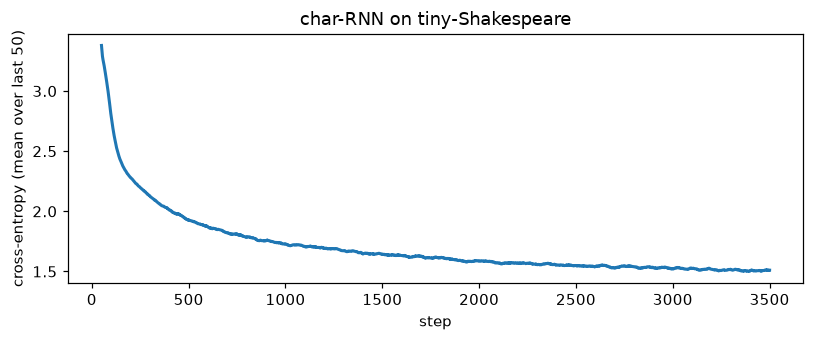

In [4]:
def train(model, steps=3500, batch_size=64, T=50, lr=2e-3, clip=5.0, seed=1):
    r = np.random.default_rng(seed)
    ms = [np.zeros_like(p) for p in model.params()]
    vs = [np.zeros_like(p) for p in model.params()]
    b1, b2, eps_adam = 0.9, 0.999, 1e-8
    hist = []
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        starts = r.integers(0, len(data) - T - 2, batch_size)
        xs = np.stack([data[s:s + T] for s in starts]).astype(int)
        ys = np.stack([data[s + 1:s + T + 1] for s in starts]).astype(int)
        loss, grads = model.loss_grads(xs, ys)
        norm = float(np.sqrt(sum((g ** 2).sum() for g in grads)))
        if norm > clip:                                     # Pascanu et al. 2013
            grads = [g * (clip / norm) for g in grads]
        for i, (p, g) in enumerate(zip(model.params(), grads)):
            ms[i] = b1 * ms[i] + (1 - b1) * g
            vs[i] = b2 * vs[i] + (1 - b2) * g * g
            m_hat = ms[i] / (1 - b1 ** step)
            v_hat = vs[i] / (1 - b2 ** step)
            p -= lr * m_hat / (np.sqrt(v_hat) + eps_adam)
        hist.append((step, loss, norm))
        if step % 500 == 0:
            print(f"step {step:>4}: loss {np.mean([h[1] for h in hist[-500:]]):.4f} | grad norm {norm:5.1f}")
    print(f"\ntrained {steps} steps of T={T} in {time.perf_counter() - t0:.0f}s | final loss {hist[-1][1]:.4f}"
          f" (uniform-char baseline: {np.log(V):.2f})")
    return np.array(hist)

model = CharRNN(V, 32, 128, rng)
print("sample BEFORE training:\n" + model.sample(data[:10], 300, 0.9, np.random.default_rng(3)).replace("\n", " / "))
hist = train(model, steps=3500)
save_ckpt(CKPT, "char_rnn_trained", metrics={"final_loss": round(float(hist[-1, 1]), 4)},
          E=model.E, Wx=model.Wx, Wh=model.Wh, b=model.b, Wy=model.Wy, by=model.by, hist=hist)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
smooth = np.convolve(hist[:, 1], np.ones(50) / 50, mode="valid")
ax.plot(hist[49:, 0], smooth, lw=2)
ax.set_xlabel("step"); ax.set_ylabel("cross-entropy (mean over last 50)")
ax.set_title("char-RNN on tiny-Shakespeare")
fig.tight_layout(); fig.savefig(FIGS / "loss_curve.png", dpi=140, bbox_inches="tight"); plt.show()

In [5]:
for t in (0.6, 0.9):
    print(f"===== sample, temperature {t} =====")
    print(model.sample(data[:24], 400, t, np.random.default_rng(7)))
    print()

===== sample, temperature 0.6 =====
 will and heart. Why come not pader i' the request the content,
On full them.

CORIOLANUS:
What I am not live to the could not like in, you shall be the people his man his majesty
brows a did a comes the patted her from the party, to ears with comes my fill me see are the son this and his childts the people
With his country by him, which he have be a man, and like to cause.

MENENIUS:
The people.


===== sample, temperature 0.9 =====
 will Coriolanuss. the Valmoner Edward.

SICINIUS:
Pargates.

MENENIUS:
What, no that make upon I amprins of our varrame of the city by your maths men thee?

CLARENCE:
Grose all thought
A give man from the ropalicions.

SICINIUS:
If we nevil lies of more latten'd besieve my rapquee onaling his your officels
bson; to bethout aught, and an for Rustence
That bleed them.

Citizens:
In for them! Say yo



## 3. Opening the state

Two views of the same vector. First, the hidden activations $h_t \in [-1, 1]^{128}$ as the model reads a prompt — every column is one unit over time; watch for units that hold value for many steps (slow state = crude memory) versus units that flicker per character. Second, the model's **beliefs** changing online: for a fixed prompt, the next-character prediction after each new letter arrives.

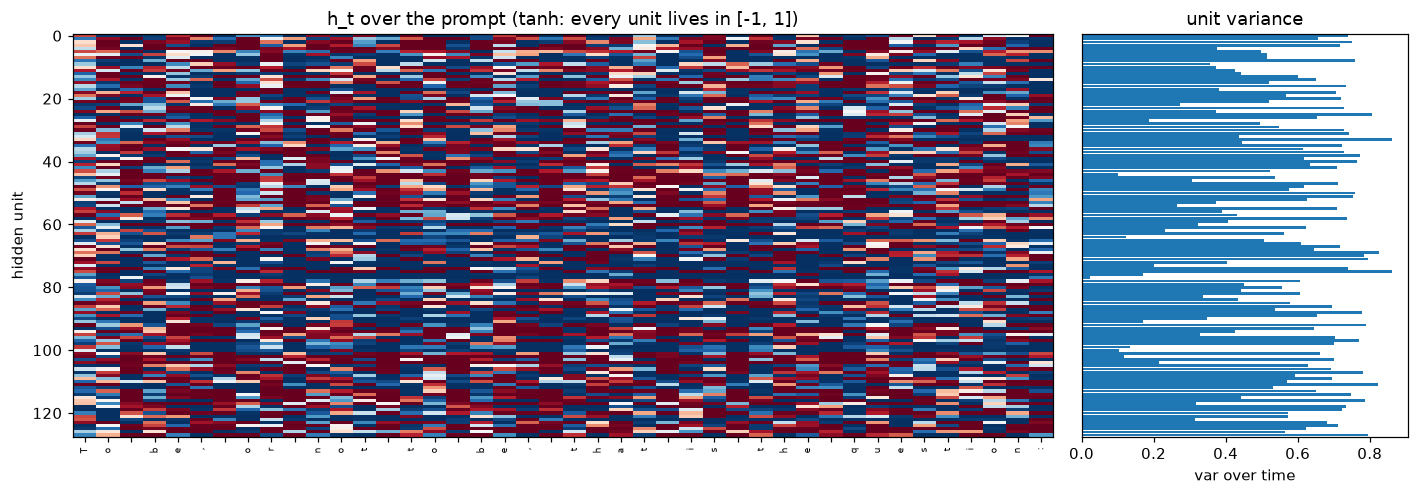

beliefs evolving (context -> top-3 next-char predictions):
             'To be' -> ' ':0.61  'e':0.12  '\n':0.05
          ' be, or ' -> 't':0.14  'h':0.10  'a':0.08
          'or not t' -> 'h':0.63  'o':0.26  'a':0.03
          't to be,' -> ' ':0.78  '\n':0.20  '-':0.01
          'be, that' -> ' ':0.85  ',':0.06  '\n':0.03
          'is the q' -> 'u':0.98  'o':0.02  'r':0.00


In [6]:
prompt = "To be, or not to be, that is the question:"
ids = np.array([c2i.get(c, 0) for c in prompt])[None, :].astype(int)
zs, hs, _ = model.forward(ids)
hs = np.array(hs)[1:, 0]                                 # (T, H)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [3, 1]})
axes[0].imshow(hs.T, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(prompt)), [c.replace("\n", "⏎") for c in prompt], rotation=90, fontsize=6)
axes[0].set_ylabel("hidden unit"); axes[0].set_title("h_t over the prompt (tanh: every unit lives in [-1, 1])")
var = hs.var(axis=0)
axes[1].barh(range(model.H), var, height=0.9)
axes[1].set_ylim(127.5, -0.5); axes[1].set_xlabel("var over time")
axes[1].set_title("unit variance"); axes[1].set_yticks([])
fig.tight_layout(); fig.savefig(FIGS / "hidden_heatmap.png", dpi=140, bbox_inches="tight"); plt.show()

print("beliefs evolving (context -> top-3 next-char predictions):")
for t in (4, 9, 14, 19, 24, 33):
    z = zs[t, 0]
    p = np.exp(z - z.max()); p /= p.sum()
    top = np.argsort(p)[::-1][:3]
    ctx = prompt[: t + 1][-8:].replace("\n", "⏎")
    print(f"  {ctx!r:>18} -> " + "  ".join(f"{i2c[i]!r}:{p[i]:.2f}" for i in top))

## 4. The measured death of signal through time

**Experiment A — forward echo (information side).** Flip one character at position 5 of a sequence and re-run the forward pass. $\|\Delta h_t\|$, averaged over many flips, is how loud that change remains $k$ characters later. If the echo halves every few steps, a character written at $t$ has effectively left the building by $t + 20$.

**Experiment B — backward gradient (learning side).** The quantity vanishing-gradient theory is actually about: $\left\|\partial L_{final} / \partial h_t\right\|$ — the gradient of the *last* position's loss with respect to each earlier state, i.e. how much "blame" a distant loss can deliver to the prefix. Per the derivation in §1, each step back multiplies by $W_{hh}^{\top}\mathrm{diag}(1-h^2)$ — a Jacobian product. Pascanu et al. (2013) tell you what should govern it: powers of $\sigma_{\max}\bigl(W_{hh}\bigr)$, discounted by the tanh gates (which are $\le 1$).

Measure both. And then check the theory's smoking gun directly: compute $\sigma_{\max}$ of the *trained* $W_{hh}$ and see whether the measured decay rates are consistent with it.

(One honesty note: experiment B isolates the *transported* pathway only — the logits pathway feeds its blame in locally at every $t$, which is healthy. The pathology we are measuring is precisely the part of learning a long prefix that can ONLY arrive through recurrent transport.)

sigma_max(W_hh) of the trained model: 4.878


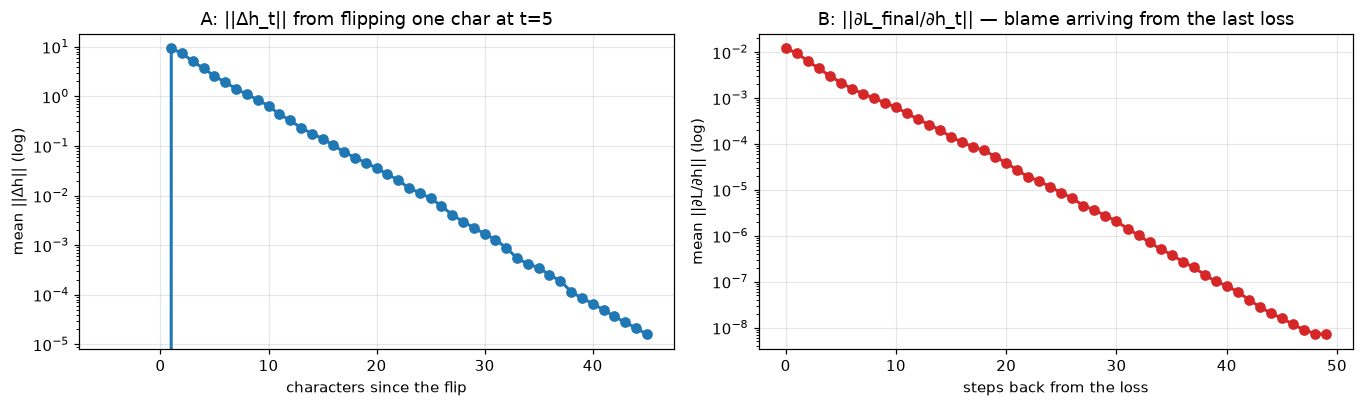

estimated half-lives: forward echo ≈ 2.3 chars | backward gradient ≈ 2.3 steps
per-step retention implied: echo 0.740 | gradient 0.743  (vs sigma_max = 4.88: amplification exists in a few directions, the tanh gates set the average)


In [7]:
T = 50
starts_b = rng.integers(0, len(data) - T - 2, 64)
xs = np.stack([data[s:s + T] for s in starts_b]).astype(int)

# --- A: forward echo of a one-character flip ---
flips = []
r = np.random.default_rng(4)
for rep in range(48):
    s = int(r.integers(0, len(data) - T - 2))
    x = data[s:s + T].astype(int)[None, :].copy()
    _, hs1, _ = model.forward(x)
    x[0, 5] = int(r.integers(0, V))
    _, hs2, _ = model.forward(x)
    flips.append([float(np.linalg.norm(h2[0] - h1[0])) for h1, h2 in zip(hs1, hs2)])
echo = np.array(flips).mean(axis=0)

# --- B: backward gradient of the LAST position's prediction loss wrt each h_t ---
zs, hs, _ = model.forward(xs)
Bt = xs.shape[0]
z = zs[-1] - zs[-1].max(axis=1, keepdims=True)
p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
g = p; g[np.arange(Bt), data[starts_b + T]] -= 1                   # real target: the char after each slice
dh = (g / Bt) @ model.Wy
back = []
for t in reversed(range(T)):
    da = dh * (1 - hs[t + 1] ** 2)
    back.append(float(np.linalg.norm(da, axis=1).mean()))
    dh = da @ model.Wh
back = np.array(back[::-1])

smax = np.linalg.svd(model.Wh, compute_uv=False)[0]
print(f"sigma_max(W_hh) of the trained model: {smax:.3f}")

def halflife_from_peak(y):
    """Fit log(y) vs steps-to-the-right of the peak; return steps per halving."""
    y = np.asarray(y, float)
    pk = int(np.argmax(y))
    yy, xx = y[pk:], np.arange(len(y) - pk)
    ok = yy > 0
    m, _ = np.polyfit(xx[ok], np.log(yy[ok]), 1)
    return -np.log(2) / m

distA = np.arange(len(echo)) - 5
distB = np.arange(T)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].semilogy(distA, echo, "o-", lw=2)
axes[0].set_title("A: ||Δh_t|| from flipping one char at t=5")
axes[0].set_xlabel("characters since the flip"); axes[0].set_ylabel("mean ||Δh|| (log)")
axes[0].grid(alpha=.3)
axes[1].semilogy(distB, back[::-1], "o-", color="tab:red", lw=2)
axes[1].set_title("B: ||∂L_final/∂h_t|| — blame arriving from the last loss")
axes[1].set_xlabel("steps back from the loss"); axes[1].set_ylabel("mean ||∂L/∂h|| (log)")
axes[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGS / "signal_decay.png", dpi=140, bbox_inches="tight"); plt.show()

hl_f, hl_b = halflife_from_peak(echo), halflife_from_peak(back[::-1])
print(f"estimated half-lives: forward echo ≈ {hl_f:.1f} chars | backward gradient ≈ {hl_b:.1f} steps")
print(f"per-step retention implied: echo {2 ** (-1 / hl_f):.3f} | gradient {2 ** (-1 / hl_b):.3f}"
      f"  (vs sigma_max = {smax:.2f}: amplification exists in a few directions, the tanh gates set the average)")

## 5. What the recurrent update buys — and what it charges

**What it buys:** order. The embedding-table window of Lab 2.1 cannot tell "king rules" from "rules king"; this model visibly *breathes* — speaker colons, capitalization after newlines, word-shaped words (check the samples). Its knowledge lives in one 128-number vector refreshed per character, and the snappy structure of English survives there.

**What it charges:** per the two curves of §4, the recurrent path is a *leaky pipe*, in both directions — and they measure the *same* leak: per-step retention ≈ 0.74, a half-life of ~2.3 steps, whether you follow a character's echo forward (A) or a loss's blame backward (B). Compound it: twenty characters downstream, a character's echo is down to ~0.2% ($0.74^{20}$); a paragraph-scale dependency (~100 chars) retains ~10⁻¹³ of its signal. That is not a training-budget issue — it is a property of the multiplication rule itself, and no amount of more epochs changes exponential decay.

And $\sigma_{\max}(W_{hh}) = 4.88$ tells you the network is *trying*: Adam happily grows large singular values whenever amplification helps; what keeps the average per-step factor at 0.74 is the tanh gates (derivative $\le 1$, and $\ll 1$ wherever activations saturate). The network spends real capacity fighting to keep the pipe half-open and still loses. The LSTM question for Lab 2.3 is exactly this budget fight: Hochreiter & Schmidhuber engineered a pathway whose default transported factor is *one* — the question next lab is whether that rewrites these two curves.

So the LSTM question for next lab is not "why gates?" in the abstract — we have the receipts for the exact number the gates must fix: the per-step retention factor of the transported term.

**Reading:**
1. Bengio, Simard, Frasconi, [*Learning Long-Term Dependencies with Gradient Descent is Difficult*](https://ieeexplore.ieee.org/document/279181) (1994) — the original diagnosis.
2. Pascanu, Mikolov, Bengio, [*On the difficulty of training recurrent neural networks*](https://arxiv.org/abs/1211.5063) (2013) — the exploding/vanishing analysis incl. the clipping we used.
3. Hochreiter & Schmidhuber, [*Long Short-Term Memory*](https://www.mitpressjournals.org/doi/10.1162/neco.1997.9.8.1735) (1997) — read it *now* with our half-life numbers in mind; next lab re-derives it.
4. Karpathy, [The Unreasonable Effectiveness of RNNs](https://karpathy.github.io/2015/05/21/rnn-effectiveness/) (2015) — the blog post this lab's training section is a hand-built homage to.
5. Olah, [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) — the standard picture, pre-read for Lab 2.3.

**Next (Lab 2.3):** the LSTM cell itself — what the separate cell state does to our two decay curves, on a synthetic copy task where the RNN is guaranteed to lose, scored at increasing distances.

---

### Reproduce

```bash
cd labs/ml/lm-internals
../mnist-internals/.venv/bin/jupyter lab     # kernel "Python (lm-labs shared)"; open 02_a_language_model_without_attention.ipynb
```

Artifacts: `checkpoints/lab22/char_rnn_trained.npz` (all six tensors + loss history), `figures/lab22/*.png`.

In [8]:
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<20} metrics={e['metrics']}")

checkpoints written this lab:
  char_rnn_trained     metrics={'final_loss': 1.5697}
